## Предсказание потребления энергии по характеристикам здания и окружения (множественная линейная регрессия)
Импорт библиотек и загрузка датасета:

In [230]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.metrics as sklmetr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [197]:
energy_train = pd.read_csv('train_energy_data.csv')
energy_test = pd.read_csv('test_energy_data.csv')
energy_train.head()

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
0,Residential,7063,76,10,29.84,Weekday,2713.95
1,Commercial,44372,66,45,16.72,Weekday,5744.99
2,Industrial,19255,37,17,14.30,Weekend,4101.24
3,Residential,13265,14,41,32.82,Weekday,3009.14
4,Commercial,13375,26,18,11.92,Weekday,3279.17


In [198]:
energy_train.shape

(1000, 7)

In [199]:
energy_test.shape

(100, 7)

In [200]:
energy_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1000 non-null   object 
 1   Square Footage       1000 non-null   int64  
 2   Number of Occupants  1000 non-null   int64  
 3   Appliances Used      1000 non-null   int64  
 4   Average Temperature  1000 non-null   float64
 5   Day of Week          1000 non-null   object 
 6   Energy Consumption   1000 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 54.8+ KB


In [201]:
energy_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        100 non-null    object 
 1   Square Footage       100 non-null    int64  
 2   Number of Occupants  100 non-null    int64  
 3   Appliances Used      100 non-null    int64  
 4   Average Temperature  100 non-null    float64
 5   Day of Week          100 non-null    object 
 6   Energy Consumption   100 non-null    float64
dtypes: float64(2), int64(3), object(2)
memory usage: 5.6+ KB


In [202]:
energy_train.describe()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption
count,1000.000,1000.000000,1000.000000,1000.000000,1000.000000
mean,25462.388,48.372000,25.606000,22.611390,4166.252570
std,14294.554,29.061972,14.105166,7.139943,933.313064
min,560.000,1.000000,1.000000,10.050000,1683.950000
25%,13169.750,22.000000,13.000000,16.475000,3509.482500
50%,25477.000,47.000000,26.000000,22.815000,4175.730000
75%,37446.250,73.250000,38.000000,28.850000,4863.850000
max,49997.000,99.000000,49.000000,34.990000,6530.600000


In [203]:
energy_train.describe(include='O')

,Building Type,Day of Week
count,1000,1000
unique,3,2
top,Residential,Weekday
freq,347,507


### EDA

In [204]:
energy_train.isna().sum()

,0
Building Type,0
Square Footage,0
Number of Occupants,0
Appliances Used,0
Average Temperature,0
Day of Week,0
Energy Consumption,0


In [205]:
energy_train['Building Type'].value_counts()

,count
Building Type,
Residential,347
Commercial,336
Industrial,317


<Axes: xlabel='Building Type', ylabel='count'>

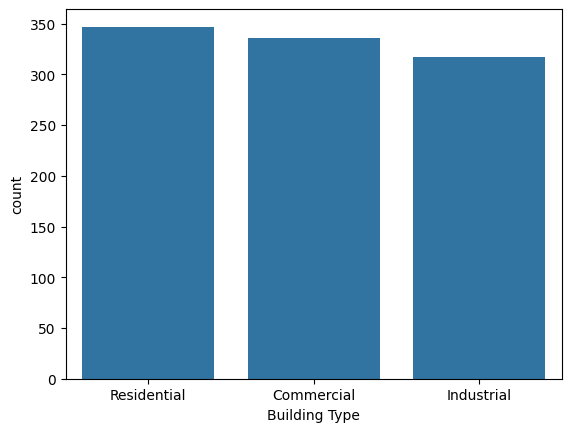

In [206]:
sns.countplot(data=energy_train, x='Building Type')

In [207]:
encoder = OneHotEncoder(categories='auto', sparse_output=False)
encoded = pd.DataFrame(encoder.fit_transform(energy_train[['Building Type']]),
                                             columns=encoder.get_feature_names_out())
energy_train_corr = pd.concat([energy_train.drop('Building Type', axis=1), encoded], axis=1)
energy_train_corr.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption,Building Type_Commercial,Building Type_Industrial,Building Type_Residential
0,7063,76,10,29.84,Weekday,2713.95,0.0,0.0,1.0
1,44372,66,45,16.72,Weekday,5744.99,1.0,0.0,0.0
2,19255,37,17,14.30,Weekend,4101.24,0.0,1.0,0.0
3,13265,14,41,32.82,Weekday,3009.14,0.0,0.0,1.0
4,13375,26,18,11.92,Weekday,3279.17,1.0,0.0,0.0


In [208]:
energy_train['Day of Week'].value_counts()

,count
Day of Week,
Weekday,507
Weekend,493


<Axes: xlabel='Day of Week', ylabel='count'>

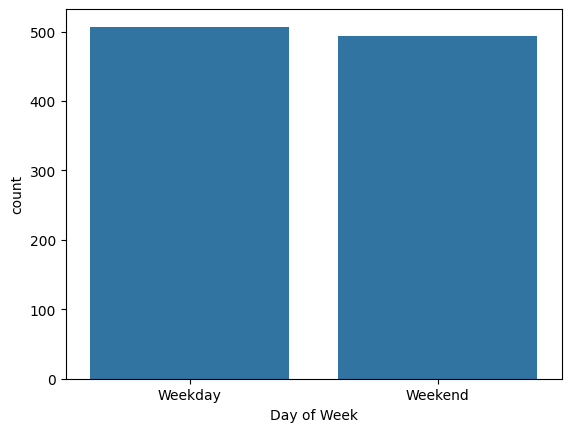

In [209]:
sns.countplot(data=energy_train, x='Day of Week')

In [210]:
encoder = OneHotEncoder(categories=[['Weekend']], sparse_output=False, handle_unknown='ignore')
encoded = pd.DataFrame(encoder.fit_transform(energy_train[['Day of Week']]),
                       columns=encoder.get_feature_names_out())
energy_train_corr = pd.concat([energy_train_corr.drop('Day of Week', axis=1), encoded], axis=1)
energy_train_corr.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,2713.95,0.0,0.0,1.0,0.0
1,44372,66,45,16.72,5744.99,1.0,0.0,0.0,0.0
2,19255,37,17,14.30,4101.24,0.0,1.0,0.0,1.0
3,13265,14,41,32.82,3009.14,0.0,0.0,1.0,0.0
4,13375,26,18,11.92,3279.17,1.0,0.0,0.0,0.0


<Axes: >

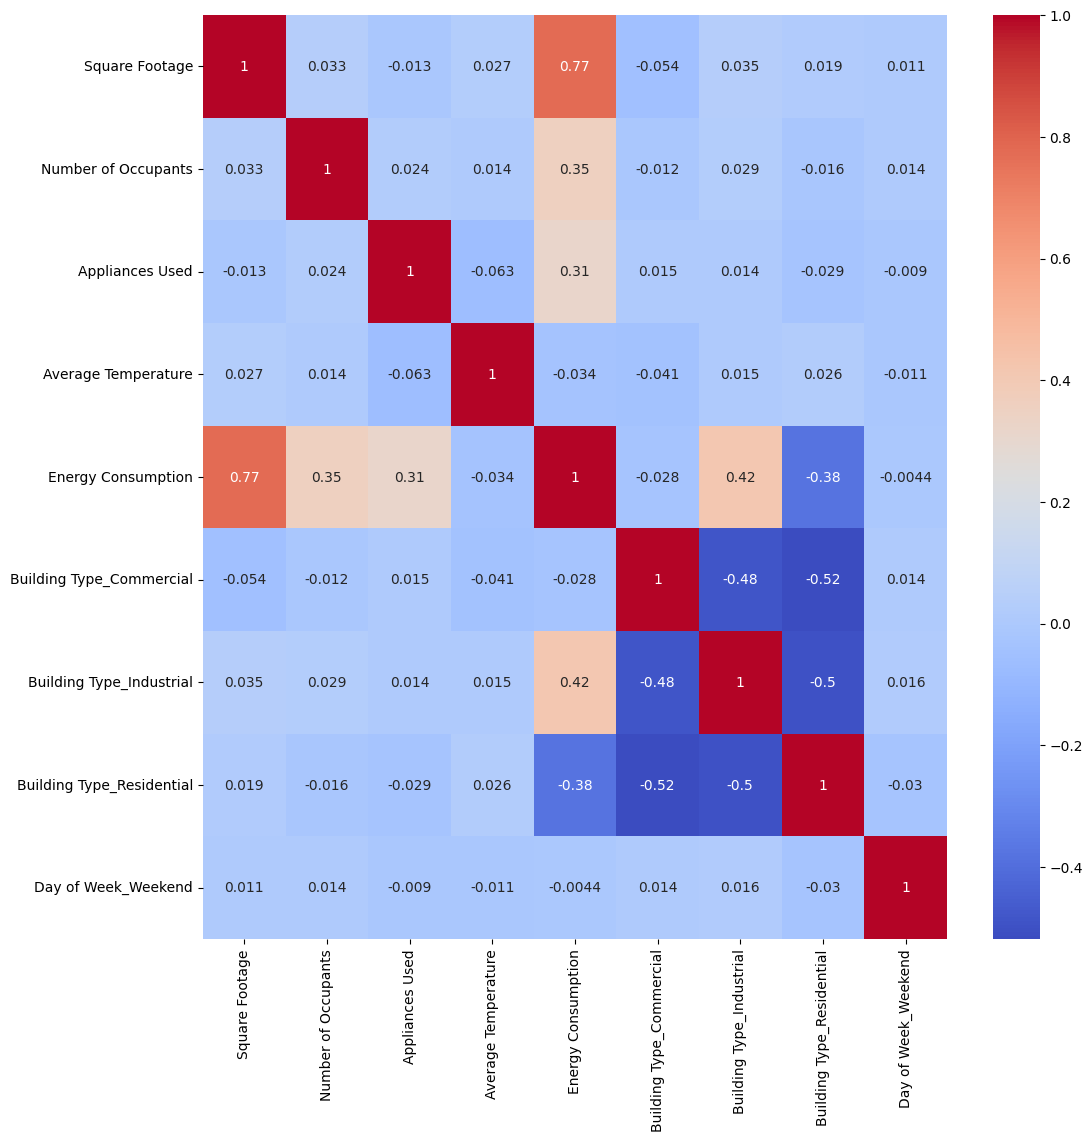

In [211]:
plt.figure(figsize=(12, 12))
sns.heatmap(data=energy_train_corr.corr(), cmap='coolwarm', annot=True)

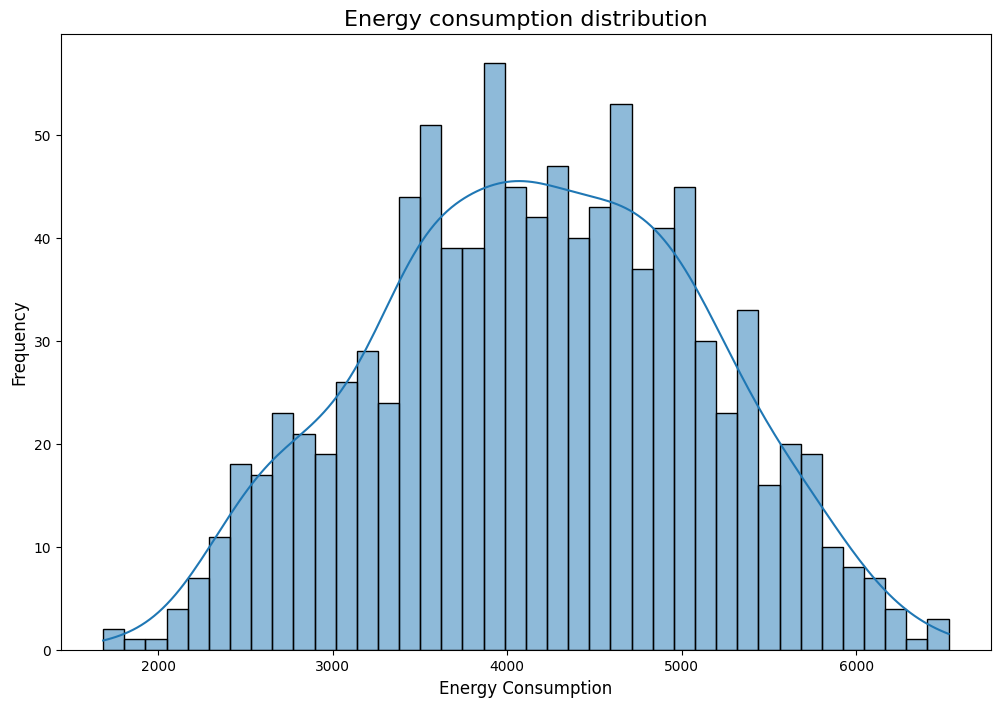

In [212]:
plt.figure(figsize=(12, 8))
sns.histplot(energy_train['Energy Consumption'], kde=True, bins=40)
plt.title('Energy consumption distribution', fontsize=16)
plt.xlabel('Energy Consumption', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

### Эксперимент А
Для первого экперимента будем работать с линейной рергессией от одного признака. В данном случае - площадь помещения, поскольку с ним у целевого признака наибольшая корреляция.

<Axes: xlabel='Square Footage', ylabel='Energy Consumption'>

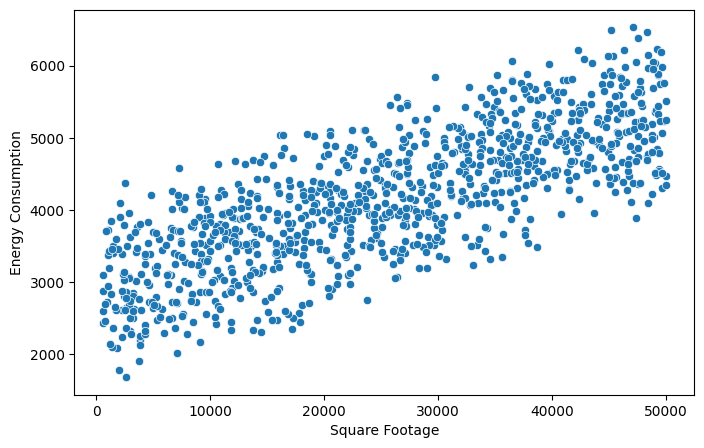

In [213]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=energy_train, x='Square Footage', y='Energy Consumption')

In [214]:
xA_train = energy_train[['Square Footage']]
yA_train = energy_train['Energy Consumption']
xA_test = energy_test[['Square Footage']]
yA_test = energy_test['Energy Consumption']

In [215]:
regressorA=LinearRegression()
regressorA.fit(xA_train, yA_train)
print(f"Коэффициент наклона: {regressorA.coef_};\nСвободный член: {regressorA.intercept_}")

Коэффициент наклона: [0.0505926];
Свободный член: 2878.044046030929


<Axes: xlabel='Square Footage', ylabel='Energy Consumption'>

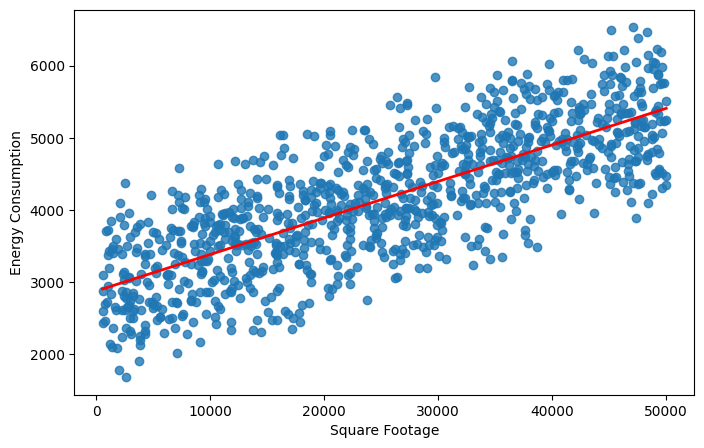

In [216]:
plt.figure(figsize=(8, 5))
sns.regplot(x='Square Footage', y='Energy Consumption', data=energy_train, ci=None, line_kws={"color": "red", "lw": 2} )

In [217]:
yA_pred = regressorA.predict(xA_test)
comparison = pd.DataFrame(({"Реальные значения:": yA_test, "Предсказания:": yA_pred}))
comparison

,Реальные значения:,Предсказания:
0,2865.57,4120.750189
1,4283.80,4273.539854
2,5067.83,5170.546731
3,4624.30,4983.961205
4,4820.59,4735.804481
...,...,...
95,3010.81,2936.782060
96,4248.49,4797.679236
97,2843.60,2956.867324
98,3348.39,2986.565183


In [218]:
maeA = sklmetr.mean_absolute_error(yA_test, yA_pred)
mseA = sklmetr.mean_squared_error(yA_test, yA_pred)
r2A = sklmetr.r2_score(yA_test, yA_pred)
print('MAE:', maeA)
print('MSE:', mseA)
print("R^2:", r2A)

MAE: 480.4150165816299
MSE: 334658.4266829627
R^2: 0.5123192151126718


### Эксперимент B
Во втором экперименте будем предсказывать энергопотребление по 2 признакам - площади и числу жильцов:

<Axes: xlabel='Number of Occupants', ylabel='Energy Consumption'>

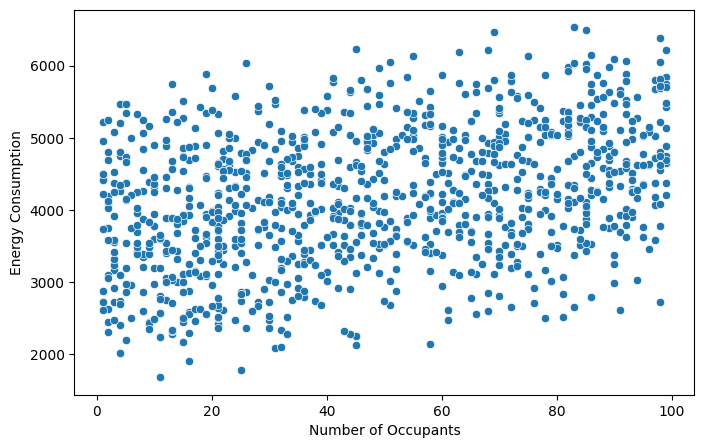

In [220]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=energy_train, x='Number of Occupants', y='Energy Consumption')

In [221]:
xB_train = energy_train[['Square Footage', 'Number of Occupants']]
yB_train = energy_train['Energy Consumption']
xB_test = energy_test[['Square Footage', 'Number of Occupants']]
yB_test = energy_test['Energy Consumption']

In [223]:
regressorB=LinearRegression()
regressorB.fit(xB_train, yB_train)
print(f"Коэффициент наклона: {regressorB.coef_};\nСвободный член: {regressorB.intercept_}")

Коэффициент наклона: [ 0.04987563 10.56528315];
Свободный член: 2385.236025904348


In [225]:
yB_pred = regressorB.predict(xB_test)
comparison = pd.DataFrame(({"Реальные значения:": yB_test, "Предсказания:": yB_pred}))
comparison

,Реальные значения:,Предсказания:
0,2865.57,3768.810397
1,4283.80,4352.611411
2,5067.83,4687.511624
3,4624.30,5348.792950
4,4820.59,4829.455618
...,...,...
95,3010.81,3298.929569
96,4248.49,4805.931249
97,2843.60,2748.204904
98,3348.39,3083.875111


In [226]:
maeB = sklmetr.mean_absolute_error(yB_test, yB_pred)
mseB = sklmetr.mean_squared_error(yB_test, yB_pred)
r2B = sklmetr.r2_score(yB_test, yB_pred)
print('MAE:', maeB)
print('MSE:', mseB)
print("R^2:", r2B)

MAE: 396.1152154999522
MSE: 236820.91652891535
R^2: 0.6548928661522403


### Эксперимент C
Линейная регрессия по всем признакам:

In [242]:
xC_train = energy_train.drop('Energy Consumption', axis=1)
yC_train = energy_train['Energy Consumption']
xC_test = energy_test.drop('Energy Consumption', axis=1)
yC_test = energy_test['Energy Consumption']

In [244]:
categorial = energy_train.select_dtypes(include=['object']).columns.to_list()

In [249]:
categorial_transformer = Pipeline([
    ('encoder', OneHotEncoder(
        sparse_output=False,
        handle_unknown='ignore',
        drop='first'
    ))
])

pipeline = Pipeline([
    ('preprocessor', ColumnTransformer([('cat', categorial_transformer, categorial)], remainder='passthrough')),
    ('model', LinearRegression())
])

In [251]:
pipeline.fit(xC_train, yC_train)
print(f"Коэффициент наклона: {pipeline.named_steps['model'].coef_};\nСвободный член: {pipeline.named_steps['model'].intercept_}")

Коэффициент наклона: [ 5.00000492e+02 -5.00000189e+02 -5.00007700e+01  4.99999869e-02
  1.00000030e+01  2.00000200e+01 -5.00004654e+00];
Свободный член: 2050.00113769724


In [252]:
yC_pred = pipeline.predict(xC_test)
comparison = pd.DataFrame(({"Реальные значения:": yC_test, "Предсказания:": yC_pred}))
comparison

,Реальные значения:,Предсказания:
0,2865.57,2865.549425
1,4283.80,4283.799561
2,5067.83,5067.849874
3,4624.30,4624.298951
4,4820.59,4820.600787
...,...,...
95,3010.81,3010.800097
96,4248.49,4248.499281
97,2843.60,2843.600224
98,3348.39,3348.400692


In [253]:
maeC = sklmetr.mean_absolute_error(yC_test, yC_pred)
mseC = sklmetr.mean_squared_error(yC_test, yC_pred)
r2C = sklmetr.r2_score(yC_test, yC_pred)
print('MAE:', maeC)
print('MSE:', mseC)
print("R^2:", r2C)

MAE: 0.012161901142540045
MSE: 0.0002015424118731763
R^2: 0.9999999997063025


### Сводная таблица метрик по экспериментам

In [255]:
metrics = pd.DataFrame([[maeA, mseA, r2A], [maeB, mseB, r2B], [maeC, mseC, r2C]],
                       index=['ExpA', 'ExpB', 'ExpC'],
                       columns=['MAE', 'MSE', 'R^2'])
metrics

,MAE,MSE,R^2
ExpA,480.415017,334658.426683,0.512319
ExpB,396.115215,236820.916529,0.654893
ExpC,0.012162,0.000202,1.000000
